<a href="https://colab.research.google.com/github/uniqueeee777/stability-aware-multiview-food-security/blob/main/01_Data_Audit_and_Construct_Diagnostics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Integrasi Google Drive dan struktur folder

In [ ]:

# ============================================================
# CELL 1 — PROJECT SETUP & GOOGLE DRIVE
# ============================================================

from google.colab import drive, files
from pathlib import Path
from datetime import datetime, timezone
from itertools import combinations
from IPython.display import display

import hashlib
import json
import platform
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt

from scipy.stats import skew, kurtosis

drive.mount("/content/drive")

# Identitas eksperimen
SEED = 20261018
PROTOCOL = "audit-v0.1"

RUN_ID = datetime.now(timezone.utc).strftime(
    "%Y%m%d_%H%M%S_UTC"
)

# Folder utama di Google Drive
ROOT = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

FOLDERS = {
    "protocol": ROOT / "00_protocol",
    "raw": ROOT / "01_data" / "01_raw",
    "processed": ROOT / "01_data" / "02_processed",
    "notebooks": ROOT / "02_notebooks",
    "tables": ROOT / "03_outputs" / "01_audit" / RUN_ID / "tables",
    "figures": ROOT / "03_outputs" / "01_audit" / RUN_ID / "figures",
    "logs": ROOT / "04_logs",
    "models": ROOT / "05_models"
}

for folder in FOLDERS.values():
    folder.mkdir(parents=True, exist_ok=True)

print("PROJECT SETUP SUCCESSFUL")
print("Project folder:", ROOT)
print("Run ID:", RUN_ID)
print("Input folder:", FOLDERS["raw"])


Mounted at /content/drive
PROJECT SETUP SUCCESSFUL
Project folder: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab
Run ID: 20261018_164126_UTC
Input folder: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/01_data/01_raw


In [ ]:

# ============================================================
# CELL 2 — UPLOAD, VALIDATE & SAVE DATA TO GOOGLE DRIVE
# FIXED VERSION
# ============================================================

from pathlib import Path
from google.colab import files
import pandas as pd
import numpy as np
import hashlib
import io

# ------------------------------------------------------------
# 1. KONFIGURASI FILE
# ------------------------------------------------------------

FILE_NAME = "MATRIX_9VAR_CLUSTERING_85KAB_2025.csv"

DATA_PATH = FOLDERS["raw"] / FILE_NAME

REQUIRED_COLS = [
    "kode_bps",
    "kode_gaul2",
    "provinsi",
    "kabupaten_kota",
    "F1_ikp_ketersediaan",
    "F2_ikp_keterjangkauan",
    "F3_ikp_pemanfaatan",
    "C1_anomali_hujan_mm",
    "C2_cdd_hari",
    "C3_hari_hujan_ekstrem",
    "A1_persen_tanpa_angkutan",
    "A2_persen_jalan_tanah_lainnya",
    "A3_persen_tanpa_pertokoan_pasar"
]

FEATURE_COLS = REQUIRED_COLS[4:]


# ------------------------------------------------------------
# 2. FUNGSI VALIDASI FILE
# ------------------------------------------------------------

def validate_csv(raw_bytes):

    temp = pd.read_csv(
        io.BytesIO(raw_bytes),
        encoding="utf-8-sig",
        dtype={
            "kode_bps": "string",
            "kode_gaul2": "string"
        }
    )

    temp.columns = temp.columns.str.strip()

    missing_cols = [
        col for col in REQUIRED_COLS
        if col not in temp.columns
    ]

    if missing_cols:
        raise ValueError(
            f"Kolom tidak tersedia: {missing_cols}"
        )

    if temp.shape[0] != 85:
        raise ValueError(
            f"Jumlah wilayah harus 85, "
            f"tetapi ditemukan {temp.shape[0]}."
        )

    if temp["kode_bps"].duplicated().any():
        raise ValueError("Duplikasi kode BPS.")

    if temp["kode_gaul2"].duplicated().any():
        raise ValueError("Duplikasi kode GAUL.")

    numeric_data = temp[FEATURE_COLS].apply(
        pd.to_numeric,
        errors="raise"
    )

    if numeric_data.isna().any().any():
        raise ValueError(
            "Missing value pada sembilan indikator."
        )

    if not np.isfinite(
        numeric_data.to_numpy(dtype=float)
    ).all():
        raise ValueError(
            "Terdapat nilai numerik tidak finite."
        )

    return temp


# ------------------------------------------------------------
# 3. CARI FILE DI DRIVE ATAU RUNTIME COLAB
# ------------------------------------------------------------

if DATA_PATH.exists():

    print("File sudah tersedia di Google Drive.")

    raw_bytes = DATA_PATH.read_bytes()

    df_check = validate_csv(raw_bytes)

else:

    # Cari file yang mungkin sudah di-upload sebelumnya,
    # termasuk yang diberi akhiran (1), (2), dan seterusnya.
    local_files = list(
        Path("/content").glob(
            "MATRIX_9VAR_CLUSTERING_85KAB_2025*.csv"
        )
    )

    local_files = sorted(
        local_files,
        key=lambda p: p.stat().st_mtime,
        reverse=True
    )

    raw_bytes = None

    for candidate in local_files:

        try:
            candidate_bytes = candidate.read_bytes()

            df_check = validate_csv(candidate_bytes)

            raw_bytes = candidate_bytes

            print(
                "File ditemukan di runtime Colab:",
                candidate.name
            )

            break

        except (ValueError, pd.errors.ParserError):
            continue

    # Jika belum ada file valid, minta upload baru
    if raw_bytes is None:

        print("Silakan upload file CSV 85 × 9.")

        uploaded = files.upload()

        if not uploaded:
            raise FileNotFoundError(
                "Tidak ada file yang di-upload."
            )

        # Ambil berdasarkan isi file, bukan nama file.
        # Aman ketika Colab mengganti nama menjadi (2).csv.
        valid_uploads = []

        for uploaded_name, content in uploaded.items():

            if not uploaded_name.lower().endswith(".csv"):
                continue

            try:

                checked = validate_csv(content)

                valid_uploads.append(
                    (uploaded_name, content, checked)
                )

            except (ValueError, pd.errors.ParserError):
                continue

        if len(valid_uploads) != 1:
            raise ValueError(
                "Diperlukan tepat satu file CSV valid "
                "berisi 85 wilayah dan 9 indikator."
            )

        uploaded_name, raw_bytes, df_check = (
            valid_uploads[0]
        )

        print("File diterima:", uploaded_name)

    # Simpan dengan nama standar ke Google Drive
    DATA_PATH.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    DATA_PATH.write_bytes(raw_bytes)

    print("File berhasil disimpan ke Google Drive.")


# ------------------------------------------------------------
# 4. HASH SHA256 UNTUK REPRODUKSIBILITAS
# ------------------------------------------------------------

def file_sha256(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


INPUT_HASH = file_sha256(DATA_PATH)


# ------------------------------------------------------------
# 5. RINGKASAN DAN FINAL CHECK
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("DATA LOADING AND VALIDATION: SUCCESS")
print("=" * 55)

print("File       :", DATA_PATH.name)
print("Lokasi     :", DATA_PATH)
print("Dimensi    :", df_check.shape)
print("Provinsi   :", df_check["provinsi"].nunique())
print("Wilayah    :", df_check["kode_bps"].nunique())
print("Indikator  :", len(FEATURE_COLS))
print("SHA256     :", INPUT_HASH)

print("\nKomposisi wilayah per provinsi:")
display(
    df_check["provinsi"]
    .value_counts()
    .sort_index()
)

print("\nPreview dataset:")
display(df_check.head(5))

print("\nCELL 2 COMPLETED — READY FOR CELL 3")


File ditemukan di runtime Colab: MATRIX_9VAR_CLUSTERING_85KAB_2025 (2).csv
File berhasil disimpan ke Google Drive.

DATA LOADING AND VALIDATION: SUCCESS
File       : MATRIX_9VAR_CLUSTERING_85KAB_2025.csv
Lokasi     : /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/01_data/01_raw/MATRIX_9VAR_CLUSTERING_85KAB_2025.csv
Dimensi    : (85, 13)
Provinsi   : 9
Wilayah    : 85
Indikator  : 9
SHA256     : ce932d322eb49cbdb6ea3b0a8768ca89c2e9e7f0722232883541d891089ca6fa

Komposisi wilayah per provinsi:


,count
provinsi,
Maluku,11
Maluku Utara,10
Nusa Tenggara Timur,22
Papua,9
Papua Barat,7
Papua Barat Daya,6
Papua Pegunungan,8
Papua Selatan,4
Papua Tengah,8



Preview dataset:


,kode_bps,kode_gaul2,provinsi,kabupaten_kota,F1_ikp_ketersediaan,F2_ikp_keterjangkauan,F3_ikp_pemanfaatan,C1_anomali_hujan_mm,C2_cdd_hari,C3_hari_hujan_ekstrem,A1_persen_tanpa_angkutan,A2_persen_jalan_tanah_lainnya,A3_persen_tanpa_pertokoan_pasar
0,8102,126264,Maluku,Maluku Tenggara,47.60,66.31,55.50,2477.786309,6.194202,35.296553,0.000000,1.621622,98.963731
1,8103,126265,Maluku,Kepulauan Tanimbar,17.10,61.41,48.97,935.928176,23.521960,17.981252,17.977528,4.054054,85.393258
2,8106,126266,Maluku,Seram Bagian Barat,39.12,64.85,64.81,2173.560519,4.326330,44.144223,2.173913,10.112360,76.086957
3,8105,126267,Maluku,Seram Bagian Timur,52.03,70.37,48.61,2374.672237,4.116225,43.158650,4.040404,19.576720,97.474747
4,8104,126257,Maluku,Buru,49.34,72.57,55.19,1544.286756,6.101740,36.537464,8.536585,19.753086,68.292683



CELL 2 COMPLETED — READY FOR CELL 3


## Pemeriksaan integritas data dan validitas rentang

In [ ]:

# ============================================================
# CELL 3 — DATA INTEGRITY & DOMAIN VALIDATION
# ============================================================

VIEWS = {
    "Food Security": [
        "F1_ikp_ketersediaan",
        "F2_ikp_keterjangkauan",
        "F3_ikp_pemanfaatan"
    ],
    "Climate Pressure": [
        "C1_anomali_hujan_mm",
        "C2_cdd_hari",
        "C3_hari_hujan_ekstrem"
    ],
    "Accessibility": [
        "A1_persen_tanpa_angkutan",
        "A2_persen_jalan_tanah_lainnya",
        "A3_persen_tanpa_pertokoan_pasar"
    ]
}

FEATURES = [
    col for group in VIEWS.values()
    for col in group
]

ID_COLS = [
    "kode_bps", "kode_gaul2",
    "provinsi", "kabupaten_kota"
]

EXPECTED_PROVINCES = {
    "Nusa Tenggara Timur": 22,
    "Maluku": 11,
    "Maluku Utara": 10,
    "Papua": 9,
    "Papua Barat": 7,
    "Papua Barat Daya": 6,
    "Papua Tengah": 8,
    "Papua Pegunungan": 8,
    "Papua Selatan": 4
}

# Baca data tanpa mengubah file sumber
df_raw = pd.read_csv(
    DATA_PATH,
    dtype={
        "kode_bps": "string",
        "kode_gaul2": "string"
    },
    encoding="utf-8-sig"
)

df = df_raw.copy()
df.columns = df.columns.str.strip()

# Pemeriksaan kolom
required = ID_COLS + FEATURES

if df.columns.duplicated().any():
    raise ValueError("Terdapat duplikasi nama kolom.")

missing_cols = [
    col for col in required
    if col not in df.columns
]

if missing_cols:
    raise ValueError(
        f"Kolom wajib tidak tersedia: {missing_cols}"
    )

# Pemeriksaan identitas
for col in ID_COLS:
    df[col] = df[col].astype("string").str.strip()

    if df[col].isna().any() or df[col].eq("").any():
        raise ValueError(f"Identitas kosong: {col}")

if len(df) != 85:
    raise ValueError("Jumlah wilayah tidak sama dengan 85.")

for col in ["kode_bps", "kode_gaul2"]:
    if df[col].duplicated().any():
        raise ValueError(f"Kode wilayah duplikat: {col}")

if df.duplicated(
    subset=["provinsi", "kabupaten_kota"]
).any():
    raise ValueError("Nama wilayah duplikat.")

if df["provinsi"].value_counts().to_dict() != EXPECTED_PROVINCES:
    raise ValueError("Komposisi provinsi tidak sesuai protokol.")

# Konversi sembilan indikator ke numerik
for col in FEATURES:
    df[col] = pd.to_numeric(
        df[col], errors="raise"
    )

X = df[FEATURES].copy()

if X.isna().any().any():
    raise ValueError("Terdapat missing pada indikator utama.")

if not np.isfinite(X.to_numpy(dtype=float)).all():
    raise ValueError("Terdapat nilai infinite / non-finite.")

if (X.nunique() <= 1).any():
    raise ValueError("Terdapat indikator konstan.")

# Indeks IKP dan persentase Podes: 0–100
for col in (
    VIEWS["Food Security"] + VIEWS["Accessibility"]
):
    if not X[col].between(0, 100).all():
        raise ValueError(f"Rentang tidak valid: {col}")

# CDD dan frekuensi hari ekstrem: 0–365
for col in [
    "C2_cdd_hari",
    "C3_hari_hujan_ekstrem"
]:
    if not X[col].between(0, 365).all():
        raise ValueError(f"Rentang tidak valid: {col}")

assert X.shape == (85, 9)

print("DATA INTEGRITY: PASSED")
print("Dimensi fitur:", X.shape)
print("Jumlah missing:", int(X.isna().sum().sum()))

display(
    df["provinsi"].value_counts().sort_index()
)

# Pemeriksaan tambahan dari master
if "qc_chirps_piksel_selisih" in df:
    print(
        "Wilayah dengan selisih piksel CHIRPS:",
        int(
            (pd.to_numeric(
                df["qc_chirps_piksel_selisih"]
            ) > 0).sum()
        )
    )

if "qc_podes_jalan_total_tercetak_inkonsisten" in df:
    print(
        "Wilayah dengan catatan total jalan Podes:",
        int(
            df[
                "qc_podes_jalan_total_tercetak_inkonsisten"
            ].eq("YA").sum()
        )
    )


DATA INTEGRITY: PASSED
Dimensi fitur: (85, 9)
Jumlah missing: 0


,count
provinsi,
Maluku,11
Maluku Utara,10
Nusa Tenggara Timur,22
Papua,9
Papua Barat,7
Papua Barat Daya,6
Papua Pegunungan,8
Papua Selatan,4
Papua Tengah,8


# Descriptive statistics dan outlier diagnostics

In [ ]:

# ============================================================
# CELL 4 — DESCRIPTIVE STATISTICS & TUKEY FLAGS
# ============================================================

summary_rows = []
outlier_rows = []

for view, columns in VIEWS.items():

    for col in columns:

        values = X[col].to_numpy(dtype=float)

        q1, q3 = np.quantile(
            values, [0.25, 0.75]
        )

        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        flagged = (values < lower) | (values > upper)

        summary_rows.append({
            "view": view,
            "variable": col,
            "n": len(values),
            "mean": np.mean(values),
            "sd": np.std(values, ddof=1),
            "median": np.median(values),
            "min": np.min(values),
            "Q1": q1,
            "Q3": q3,
            "max": np.max(values),
            "IQR": iqr,
            "skewness": skew(values, bias=False),
            "excess_kurtosis": kurtosis(
                values, fisher=True, bias=False
            ),
            "n_tukey_flags": int(flagged.sum())
        })

        for idx in np.where(flagged)[0]:

            outlier_rows.append({
                "provinsi": df.iloc[idx]["provinsi"],
                "kabupaten_kota": df.iloc[idx]["kabupaten_kota"],
                "variable": col,
                "value": values[idx],
                "lower_fence": lower,
                "upper_fence": upper
            })

descriptive = pd.DataFrame(summary_rows)

outliers = pd.DataFrame(
    outlier_rows,
    columns=[
        "provinsi", "kabupaten_kota",
        "variable", "value",
        "lower_fence", "upper_fence"
    ]
)

display(descriptive.round(3))
display(outliers)

# Simpan seluruh hasil
descriptive.to_csv(
    FOLDERS["tables"] / "table01_descriptive.csv",
    index=False
)

outliers.to_csv(
    FOLDERS["tables"] / "tukey_flags_review.csv",
    index=False
)

print("Descriptive statistics saved.")
print("Total flagged observations:", len(outliers))


,view,variable,n,mean,sd,median,min,Q1,Q3,max,IQR,skewness,excess_kurtosis,n_tukey_flags
0,Food Security,F1_ikp_ketersediaan,85,37.349,13.944,40.190,8.350,24.610,47.610,66.350,23.000,-0.184,-0.859,0
1,Food Security,F2_ikp_keterjangkauan,85,65.841,12.338,68.990,31.150,58.720,75.030,84.480,16.310,-0.999,0.471,2
2,Food Security,F3_ikp_pemanfaatan,85,51.659,14.454,55.080,14.300,44.110,60.980,80.870,16.870,-0.731,0.331,4
3,Climate Pressure,C1_anomali_hujan_mm,85,829.452,685.289,591.111,-203.986,320.956,1256.807,2949.960,935.851,0.981,0.525,1
4,Climate Pressure,C2_cdd_hari,85,13.938,13.762,7.586,2.584,5.033,17.308,66.714,12.275,1.745,2.523,8
5,Climate Pressure,C3_hari_hujan_ekstrem,85,21.443,10.394,20.439,3.493,13.215,27.875,48.900,14.660,0.344,-0.489,0
6,Accessibility,A1_persen_tanpa_angkutan,85,26.041,27.985,16.185,0.000,2.174,40.252,95.536,38.078,0.931,-0.287,0
7,Accessibility,A2_persen_jalan_tanah_lainnya,85,22.238,27.159,10.526,0.000,1.622,35.938,94.273,34.316,1.324,0.616,3
8,Accessibility,A3_persen_tanpa_pertokoan_pasar,85,84.649,12.773,87.770,33.333,81.319,92.623,98.964,11.304,-1.891,4.331,6


,provinsi,kabupaten_kota,variable,value,lower_fence,upper_fence
0,Papua Pegunungan,Nduga,F2_ikp_keterjangkauan,31.150000,34.255000,99.495000
1,Papua Pegunungan,Yahukimo,F2_ikp_keterjangkauan,31.820000,34.255000,99.495000
2,Papua Pegunungan,Nduga,F3_ikp_pemanfaatan,18.520000,18.805000,86.285000
3,Papua Pegunungan,Tolikara,F3_ikp_pemanfaatan,14.300000,18.805000,86.285000
4,Papua Tengah,Intan Jaya,F3_ikp_pemanfaatan,16.230000,18.805000,86.285000
5,Papua Tengah,Puncak,F3_ikp_pemanfaatan,15.560000,18.805000,86.285000
6,Maluku,Kota Ambon,C1_anomali_hujan_mm,2949.960050,-1082.820003,2660.583884
7,Nusa Tenggara Timur,Alor,C2_cdd_hari,40.556413,-13.380101,35.721569
8,Nusa Tenggara Timur,Flores Timur,C2_cdd_hari,47.864325,-13.380101,35.721569
9,Nusa Tenggara Timur,Kota Kupang,C2_cdd_hari,48.962738,-13.380101,35.721569


Descriptive statistics saved.
Total flagged observations: 24


# Visualisasi distribusi sembilan indikator

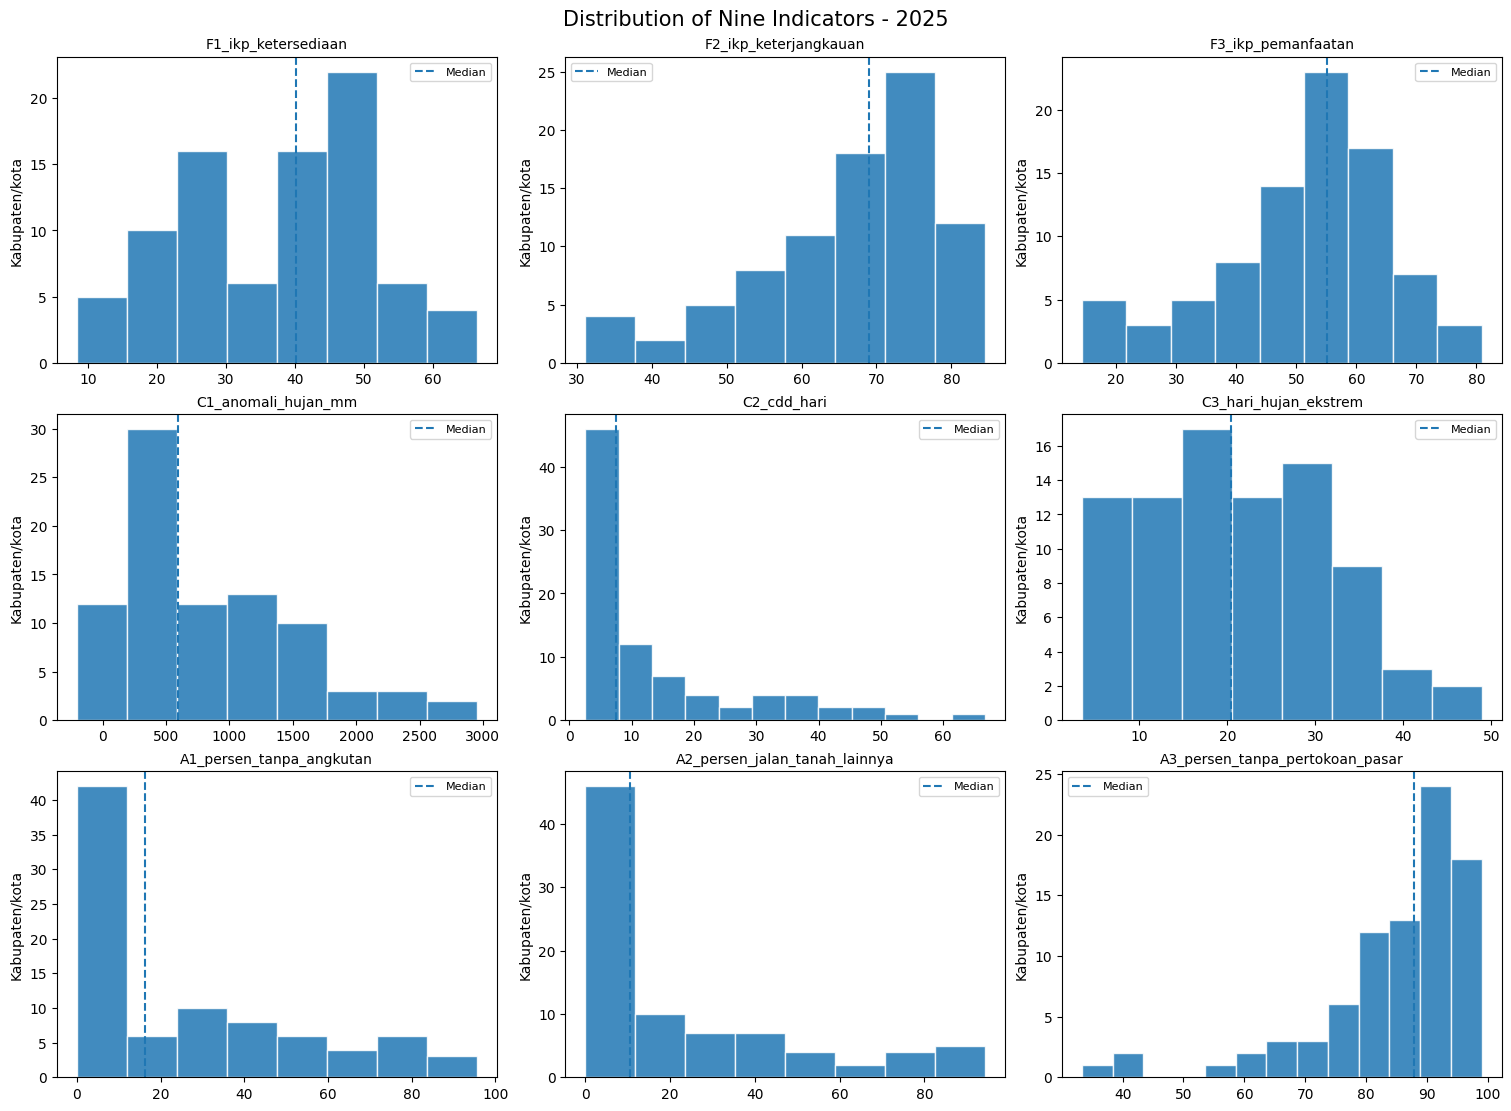

In [ ]:

# ============================================================
# CELL 5 — INDICATOR DISTRIBUTIONS
# ============================================================

fig, axes = plt.subplots(
    3, 3,
    figsize=(15, 11),
    constrained_layout=True
)

for ax, col in zip(axes.flat, FEATURES):

    values = X[col]

    ax.hist(
        values,
        bins="auto",
        edgecolor="white",
        alpha=0.85
    )

    ax.axvline(
        values.median(),
        linestyle="--",
        linewidth=1.5,
        label="Median"
    )

    ax.set_title(col, fontsize=10)
    ax.set_ylabel("Kabupaten/kota")
    ax.legend(fontsize=8)

fig.suptitle(
    "Distribution of Nine Indicators - 2025",
    fontsize=15
)

fig.savefig(
    FOLDERS["figures"] / "fig01_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Pearson, Spearman, dan redundancy diagnostics

,variable_1,variable_2,view_1,view_2,pearson_r,spearman_rho,abs_pearson,abs_difference
22,C1_anomali_hujan_mm,C3_hari_hujan_ekstrem,Climate Pressure,Climate Pressure,0.848,0.816,0.848,0.033
8,F2_ikp_keterjangkauan,F3_ikp_pemanfaatan,Food Security,Food Security,0.767,0.647,0.767,0.119
33,A1_persen_tanpa_angkutan,A2_persen_jalan_tanah_lainnya,Accessibility,Accessibility,0.727,0.733,0.727,0.006
26,C2_cdd_hari,C3_hari_hujan_ekstrem,Climate Pressure,Climate Pressure,-0.674,-0.671,0.674,0.002
19,F3_ikp_pemanfaatan,A2_persen_jalan_tanah_lainnya,Food Security,Accessibility,-0.672,-0.510,0.672,0.163
13,F2_ikp_keterjangkauan,A2_persen_jalan_tanah_lainnya,Food Security,Accessibility,-0.669,-0.636,0.669,0.033
12,F2_ikp_keterjangkauan,A1_persen_tanpa_angkutan,Food Security,Accessibility,-0.644,-0.615,0.644,0.029
18,F3_ikp_pemanfaatan,A1_persen_tanpa_angkutan,Food Security,Accessibility,-0.530,-0.444,0.530,0.086
1,F1_ikp_ketersediaan,F3_ikp_pemanfaatan,Food Security,Food Security,0.494,0.438,0.494,0.055
6,F1_ikp_ketersediaan,A2_persen_jalan_tanah_lainnya,Food Security,Accessibility,-0.470,-0.433,0.470,0.037


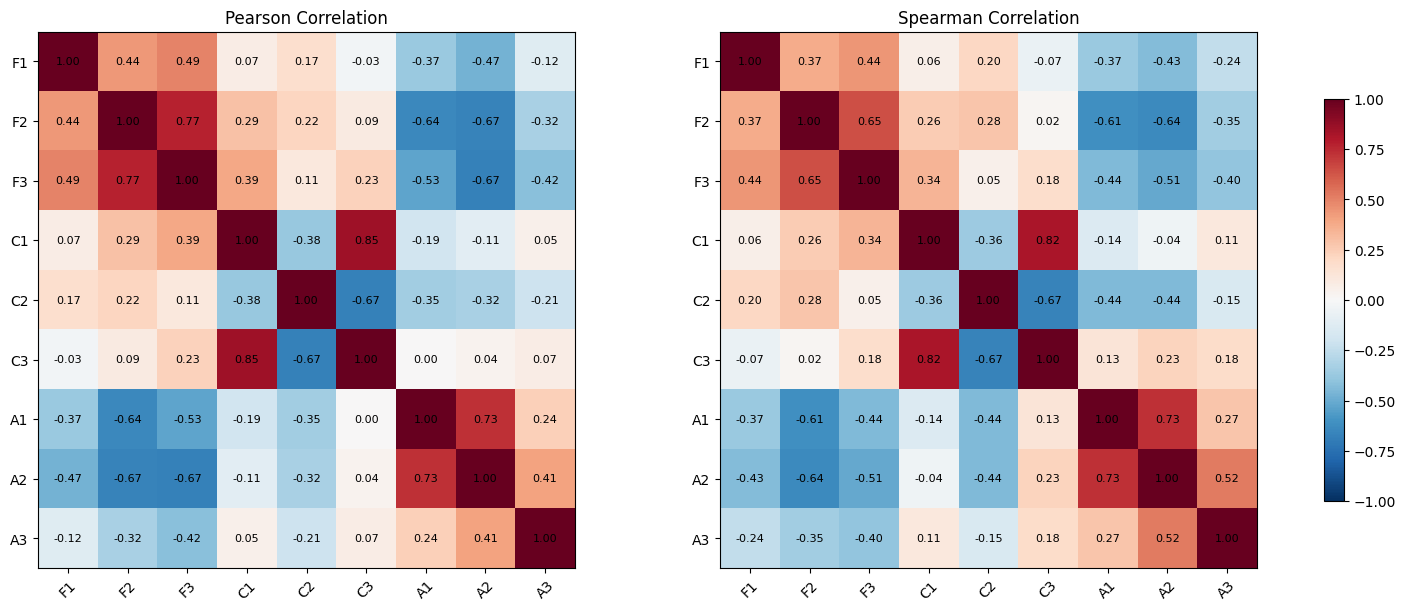

In [ ]:

# ============================================================
# CELL 6 — CORRELATION & REDUNDANCY DIAGNOSTICS
# ============================================================

pearson = X.corr(method="pearson")
spearman = X.corr(method="spearman")

# Seluruh 36 pasangan indikator
pairs = []

feature_view = {
    col: view
    for view, columns in VIEWS.items()
    for col in columns
}

for a, b in combinations(FEATURES, 2):

    rp = float(pearson.loc[a, b])
    rs = float(spearman.loc[a, b])

    pairs.append({
        "variable_1": a,
        "variable_2": b,
        "view_1": feature_view[a],
        "view_2": feature_view[b],
        "pearson_r": rp,
        "spearman_rho": rs,
        "abs_pearson": abs(rp),
        "abs_difference": abs(rp - rs)
    })

correlation_pairs = (
    pd.DataFrame(pairs)
    .sort_values(
        "abs_pearson",
        ascending=False
    )
)

display(correlation_pairs.head(15).round(3))

# Simpan matriks dan pasangan korelasi
pearson.to_csv(
    FOLDERS["tables"] / "correlation_pearson.csv"
)

spearman.to_csv(
    FOLDERS["tables"] / "correlation_spearman.csv"
)

correlation_pairs.to_csv(
    FOLDERS["tables"] / "correlation_pairs.csv",
    index=False
)

# Visualisasi dua matriks korelasi
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6),
    constrained_layout=True
)

labels = [
    col.split("_")[0]
    for col in FEATURES
]

for ax, matrix, title in zip(
    axes,
    [pearson, spearman],
    ["Pearson Correlation", "Spearman Correlation"]
):

    im = ax.imshow(
        matrix.to_numpy(),
        cmap="RdBu_r",
        vmin=-1,
        vmax=1
    )

    ax.set_xticks(range(9), labels, rotation=45)
    ax.set_yticks(range(9), labels)

    for i in range(9):
        for j in range(9):
            ax.text(
                j, i,
                f"{matrix.iloc[i, j]:.2f}",
                ha="center",
                va="center",
                fontsize=8
            )

    ax.set_title(title)

fig.colorbar(im, ax=axes, shrink=0.75)

fig.savefig(
    FOLDERS["figures"] / "fig02_correlations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## Diagnostik struktur indikator dan pengaruh provinsi

In [ ]:

# ============================================================
# CELL 8 — STRUCTURAL DISTRIBUTION & PROVINCE DIAGNOSTICS
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display

assert X.shape == (85, 9)
assert df.index.equals(X.index)

C1 = "C1_anomali_hujan_mm"
A1 = "A1_persen_tanpa_angkutan"
A2 = "A2_persen_jalan_tanah_lainnya"
A3 = "A3_persen_tanpa_pertokoan_pasar"

# 1. Distribusi kondisi khusus
checks = pd.DataFrame([
    {"pemeriksaan": "C1 > 0", "n_wilayah": int((X[C1] > 0).sum())},
    {"pemeriksaan": "C1 < 0", "n_wilayah": int((X[C1] < 0).sum())},
    {"pemeriksaan": "A1 = 0", "n_wilayah": int((X[A1] == 0).sum())},
    {"pemeriksaan": "A2 = 0", "n_wilayah": int((X[A2] == 0).sum())},
    {"pemeriksaan": "A3 >= 80", "n_wilayah": int((X[A3] >= 80).sum())},
    {"pemeriksaan": "A3 >= 90", "n_wilayah": int((X[A3] >= 90).sum())}
])

display(checks)

print("\nWilayah dengan anomali hujan negatif:")
display(
    df.loc[
        X[C1] < 0,
        ["provinsi", "kabupaten_kota", C1]
    ]
)

# 2. Perbedaan profil rata-rata provinsi
province_means = (
    df.groupby("provinsi")[FEATURES]
    .mean()
)

print("\nRata-rata indikator per provinsi:")
display(province_means.round(2))

# 3. Korelasi keseluruhan vs dalam-provinsi
# Centering digunakan HANYA untuk diagnostik,
# bukan mengubah data clustering.

X_centered = X.copy()

for col in FEATURES:
    group_mean = X[col].groupby(
        df["provinsi"]
    ).transform("mean")

    X_centered[col] = X[col] - group_mean

selected_pairs = [
    ("F2_ikp_keterjangkauan", "F3_ikp_pemanfaatan"),
    ("C1_anomali_hujan_mm", "C3_hari_hujan_ekstrem"),
    ("A1_persen_tanpa_angkutan", "A2_persen_jalan_tanah_lainnya"),
    ("F2_ikp_keterjangkauan", "A2_persen_jalan_tanah_lainnya"),
    ("F3_ikp_pemanfaatan", "A2_persen_jalan_tanah_lainnya")
]

records = []

for a, b in selected_pairs:
    records.append({
        "variable_1": a,
        "variable_2": b,
        "r_overall": X[a].corr(X[b]),
        "r_within_province": X_centered[a].corr(
            X_centered[b]
        )
    })

province_corr = pd.DataFrame(records)

print("\nKorelasi sebelum dan sesudah centering:")
display(province_corr.round(3))

# 4. Simpan
checks.to_csv(
    FOLDERS["tables"] / "structural_indicators.csv",
    index=False
)

province_means.to_csv(
    FOLDERS["tables"] / "province_indicator_means.csv"
)

province_corr.to_csv(
    FOLDERS["tables"] / "within_province_correlations.csv",
    index=False
)

print("\nCELL 8 COMPLETED")


,pemeriksaan,n_wilayah
0,C1 > 0,82
1,C1 < 0,3
2,A1 = 0,11
3,A2 = 0,12
4,A3 >= 80,65
5,A3 >= 90,37



Wilayah dengan anomali hujan negatif:


,provinsi,kabupaten_kota,C1_anomali_hujan_mm
23,Nusa Tenggara Timur,Malaka,-18.005423
60,Papua,Keerom,-28.453845
69,Papua Pegunungan,Pegunungan Bintang,-203.986184



Rata-rata indikator per provinsi:


,F1_ikp_ketersediaan,F2_ikp_keterjangkauan,F3_ikp_pemanfaatan,C1_anomali_hujan_mm,C2_cdd_hari,C3_hari_hujan_ekstrem,A1_persen_tanpa_angkutan,A2_persen_jalan_tanah_lainnya,A3_persen_tanpa_pertokoan_pasar
provinsi,,,,,,,,,
Maluku,38.04,67.37,57.52,1963.37,9.44,34.54,7.95,20.68,84.52
Maluku Utara,34.28,77.82,61.72,1300.45,8.47,27.30,11.89,8.29,86.34
Nusa Tenggara Timur,46.17,72.71,54.59,400.81,31.21,9.79,6.13,2.19,80.37
Papua,39.69,64.06,56.84,405.10,5.70,21.69,36.68,11.86,74.32
Papua Barat,41.58,67.91,55.40,760.13,11.53,24.39,24.69,21.26,93.59
Papua Barat Daya,33.46,70.15,53.94,1264.93,6.40,32.58,34.59,17.22,83.32
Papua Pegunungan,24.18,40.83,28.71,222.91,10.28,16.68,61.33,63.08,89.10
Papua Selatan,38.90,60.36,51.33,1608.36,4.96,29.09,68.02,57.60,91.33
Papua Tengah,24.96,54.59,35.26,288.86,4.62,17.89,49.90,54.70,91.47



Korelasi sebelum dan sesudah centering:


,variable_1,variable_2,r_overall,r_within_province
0,F2_ikp_keterjangkauan,F3_ikp_pemanfaatan,0.767,0.599
1,C1_anomali_hujan_mm,C3_hari_hujan_ekstrem,0.848,0.799
2,A1_persen_tanpa_angkutan,A2_persen_jalan_tanah_lainnya,0.727,0.502
3,F2_ikp_keterjangkauan,A2_persen_jalan_tanah_lainnya,-0.669,-0.235
4,F3_ikp_pemanfaatan,A2_persen_jalan_tanah_lainnya,-0.672,-0.478



CELL 8 COMPLETED


## Menguji struktur jarak dan komplementaritas antar-view

In [ ]:

# ============================================================
# CELL 9 — MULTI-VIEW DISTANCE STRUCTURE
# DIAGNOSTICS ONLY — NO CLUSTERING
# ============================================================

from scipy.spatial.distance import pdist
from scipy.stats import spearmanr
from itertools import combinations

# 1. Standardisasi diagnostik sementara
# Menggunakan sample standard deviation (ddof=1)

means = X.mean()
sds = X.std(ddof=1)

if (sds <= 0).any():
    raise ValueError("Variabel konstan ditemukan.")

Z_audit = (X - means) / sds

# 2. Jarak setiap view
view_distances = {}

for view, cols in VIEWS.items():

    matrix = Z_audit[cols].to_numpy(
        dtype=float
    )

    view_distances[view] = (
        pdist(matrix, metric="euclidean")
        / np.sqrt(len(cols))
    )

# 3. Korelasi antarvektor jarak
distance_records = []

for view_a, view_b in combinations(VIEWS, 2):

    rho = spearmanr(
        view_distances[view_a],
        view_distances[view_b]
    ).statistic

    distance_records.append({
        "view_1": view_a,
        "view_2": view_b,
        "distance_spearman": float(rho)
    })

distance_comparison = pd.DataFrame(
    distance_records
)

print("Korelasi antar-view berdasarkan jarak:")
display(distance_comparison.round(3))

# 4. Jarak dalam vs antarprovinsi
n = len(df)
idx_i, idx_j = np.triu_indices(n, k=1)

province_array = df["provinsi"].to_numpy()

same_province = (
    province_array[idx_i]
    == province_array[idx_j]
)

province_distance_records = []

for view, d in view_distances.items():

    within = d[same_province].mean()
    between = d[~same_province].mean()

    province_distance_records.append({
        "view": view,
        "within_province": float(within),
        "between_province": float(between),
        "within_between_ratio": float(
            within / between
        )
    })

province_distance = pd.DataFrame(
    province_distance_records
)

print("\nStruktur jarak menurut provinsi:")
display(province_distance.round(3))

# 5. Simpan hasil diagnostik
distance_comparison.to_csv(
    FOLDERS["tables"] / "view_distance_comparison.csv",
    index=False
)

province_distance.to_csv(
    FOLDERS["tables"] / "province_distance_structure.csv",
    index=False
)

print("\nCELL 9 COMPLETED")


Korelasi antar-view berdasarkan jarak:


,view_1,view_2,distance_spearman
0,Food Security,Climate Pressure,-0.009
1,Food Security,Accessibility,0.441
2,Climate Pressure,Accessibility,0.080



Struktur jarak menurut provinsi:


,view,within_province,between_province,within_between_ratio
0,Food Security,0.817,1.304,0.627
1,Climate Pressure,0.725,1.290,0.562
2,Accessibility,0.832,1.280,0.650



CELL 9 COMPLETED
